# Phase 2 – Data Quality, Feature Engineering, EDA & Hypothesis Testing
**Sigmoid case study – Bike Sharing Demand**


## 0. Setup – upload data and create the project modules

In [1]:
import os

# Create required project directories
for d in ["src", "outputs/charts", "outputs/model_results"]:
    os.makedirs(d, exist_ok=True)

# Check uploaded files
print("Uploaded files:", sorted(
    f for f in os.listdir(".")
    if f in ["hour.csv", "day.csv", "Readme.txt"]
))

Uploaded files: ['Readme.txt', 'day.csv', 'hour.csv']


In [2]:
%%writefile src/preprocessing.py
"""
Loading and cleaning for the Bike Sharing dataset.

Rules followed:
* Raw CSVs are never modified on disk; every function returns a new DataFrame.
* Nothing is deleted. Bad values are corrected and FLAGGED so the change is visible.
* Every cleaning decision is listed in CLEANING_LOG (shown in the notebook / report).
"""
from __future__ import annotations

import numpy as np
import pandas as pd

# Readme: values were divided by these maxima -> multiply back for human-readable units
TEMP_MAX_C, ATEMP_MAX_C, HUM_MAX, WIND_MAX = 41, 50, 100, 67

# Days on which the system was (partly) shut down or data are incomplete (< 22 recorded hours).
# Identified in Phase 1; kept for modelling but flagged.
DISRUPTED_DAYS = pd.to_datetime([
    "2011-01-18", "2011-01-26", "2011-01-27", "2011-02-22",
    "2011-08-27", "2011-08-28", "2012-10-29", "2012-10-30",
])

CLEANING_LOG = [
    ("hum == 0 on 2011-03-10 (22 hourly rows, 1 daily row)",
     "Physically impossible -> sensor error. Replaced with the mean humidity of the same hour on "
     "the previous and next day (daily file: mean of neighbouring days). Flag column `hum_imputed`."),
    ("weathersit == 4 (3 hourly rows)",
     "Too rare to learn from. New column `weather` merges 4 into 3 ('rain/snow'). Raw column kept."),
    ("windspeed == 0 (12.5% of hours; next value is 0.0896)",
     "Likely 'calm / not recorded'. Kept unchanged, flagged in `wind_zero`. Low impact on demand."),
    ("165 missing hours (mostly 02:00-05:00; storm shutdowns)",
     "Not filled with invented rows for EDA/model training. Zero-rental hours appear to be absent, "
     "so night-time averages are slightly overstated. Storm days flagged in `disrupted_day`."),
    ("High cnt values (up to 977/hr)",
     "Genuine commute peaks (Phase 1, Step 10). Not removed."),
]


def load_hour(path: str = "data/hour.csv") -> pd.DataFrame:
    return pd.read_csv(path, parse_dates=["dteday"])


def load_day(path: str = "data/day.csv") -> pd.DataFrame:
    return pd.read_csv(path, parse_dates=["dteday"])


def _impute_hourly_humidity(df: pd.DataFrame) -> pd.DataFrame:
    bad = df["hum"] == 0
    df["hum_imputed"] = bad.astype(int)
    if not bad.any():
        return df
    lookup = df.loc[~bad].set_index(["dteday", "hr"])["hum"]
    for idx in df.index[bad]:
        d, h = df.at[idx, "dteday"], df.at[idx, "hr"]
        neighbours = [lookup.get((d + pd.Timedelta(days=k), h)) for k in (-1, 1)]
        neighbours = [v for v in neighbours if v is not None and not pd.isna(v)]
        df.at[idx, "hum"] = np.mean(neighbours) if neighbours else df.loc[~bad, "hum"].median()
    return df


def clean_hour(raw: pd.DataFrame) -> pd.DataFrame:
    df = raw.copy().sort_values(["dteday", "hr"]).reset_index(drop=True)
    df["timestamp"] = df["dteday"] + pd.to_timedelta(df["hr"], unit="h")
    df = _impute_hourly_humidity(df)
    df["weather"] = df["weathersit"].clip(upper=3)
    df["wind_zero"] = (df["windspeed"] == 0).astype(int)
    df["disrupted_day"] = df["dteday"].isin(DISRUPTED_DAYS).astype(int)
    return add_physical_units(df)


def clean_day(raw: pd.DataFrame) -> pd.DataFrame:
    df = raw.copy().sort_values("dteday").reset_index(drop=True)
    bad = df["hum"] == 0
    df["hum_imputed"] = bad.astype(int)
    for idx in df.index[bad]:
        neigh = df.loc[[i for i in (idx - 1, idx + 1) if i in df.index and not bad[i]], "hum"]
        df.at[idx, "hum"] = neigh.mean()
    df["weather"] = df["weathersit"].clip(upper=3)
    df["disrupted_day"] = df["dteday"].isin(DISRUPTED_DAYS).astype(int)
    return add_physical_units(df)


def add_physical_units(df: pd.DataFrame) -> pd.DataFrame:
    """De-normalise for readable charts and for the prototype (no new information)."""
    df["temp_c"] = df["temp"] * TEMP_MAX_C
    df["atemp_c"] = df["atemp"] * ATEMP_MAX_C
    df["hum_pct"] = df["hum"] * HUM_MAX
    df["wind_unscaled"] = df["windspeed"] * WIND_MAX   # Readme does not state the unit
    return df


Writing src/preprocessing.py


In [3]:
%%writefile src/feature_engineering.py
"""
Feature engineering. Every feature uses only information known BEFORE the hour starts
(calendar + weather for that hour, which in deployment comes from a weather forecast).
No feature uses `casual`, `registered`, or future rows.
"""
from __future__ import annotations

import numpy as np
import pandas as pd

MORNING_PEAK = (7, 8, 9)
EVENING_PEAK = (16, 17, 18, 19)
PEAK_HOURS = MORNING_PEAK + EVENING_PEAK
NIGHT_HOURS = (0, 1, 2, 3, 4, 5)

FEATURE_RATIONALE = {
    "hr":            "Hour of day - the single strongest driver (commute vs night).",
    "weekday":       "Day of week (0=Sun). Captures Fri/Mon effects beyond the working-day flag.",
    "workingday":    "Commuting happens on working days; changes the whole daily shape.",
    "holiday":       "Public holidays behave like weekends even on Mon-Fri.",
    "is_weekend":    "Sat/Sun indicator - leisure pattern (midday peak).",
    "mnth":          "Month - seasonal temperature/daylight cycle.",
    "season":        "Coarser seasonal signal from the source data.",
    "yr":            "Growth of the system (2012 ~ +63%). Lets the model learn the level shift.",
    "morning_peak":  "Working day AND 07-09 - morning commute window.",
    "evening_peak":  "Working day AND 16-19 - evening commute window.",
    "rush_hour":     "Either commute window on a working day - where shortages are most likely.",
    "night":         "00-05 - near-zero demand; useful window for rebalancing trucks.",
    "hr_sin/hr_cos": "Cyclical hour: tells linear models that 23:00 is next to 00:00.",
    "mnth_sin/mnth_cos": "Cyclical month: December is next to January.",
    "weather":       "1 clear, 2 mist/cloud, 3 rain/snow (4 merged into 3 - only 3 rows).",
    "temp":          "Temperature (normalised). Riding is weather-sensitive.",
    "temp_sq":       "Lets a linear model capture 'too hot' - demand flattens/falls at high temps.",
    "hum":           "Humidity - proxy for discomfort and rain.",
    "windspeed":     "Wind - discomfort on a bike.",
}

EXCLUDED_COLUMNS = {
    "casual":      "Leakage: casual + registered = cnt exactly. Unknown before the hour ends.",
    "registered":  "Leakage: same reason as casual.",
    "cnt":         "Target.",
    "instant":     "Row index; it is a disguised time trend with no causal meaning. `yr` covers the trend explicitly.",
    "dteday":      "Raw date string; decomposed into yr/mnth/weekday instead.",
    "timestamp":   "Helper for sorting/splitting, not a feature.",
    "atemp":       "'Feels-like' temperature, correlation with temp ~0.99 -> redundant; kept out to avoid collinearity.",
    "weathersit":  "Replaced by `weather` (category 4 merged into 3).",
    "hum_imputed / wind_zero / disrupted_day": "Data-quality flags for analysis, not demand drivers.",
    "temp_c / atemp_c / hum_pct / wind_unscaled": "Same information as the scaled columns, used only for readable charts/app.",
}

MODEL_FEATURES = [
    "hr", "weekday", "workingday", "holiday", "is_weekend", "mnth", "season", "yr",
    "morning_peak", "evening_peak", "rush_hour", "night",
    "hr_sin", "hr_cos", "mnth_sin", "mnth_cos",
    "weather", "temp", "temp_sq", "hum", "windspeed",
]


def add_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["is_weekend"] = out["weekday"].isin([0, 6]).astype(int)
    if "hr" in out:
        hr = out["hr"]
        out["morning_peak"] = (hr.isin(MORNING_PEAK) & (out["workingday"] == 1)).astype(int)
        out["evening_peak"] = (hr.isin(EVENING_PEAK) & (out["workingday"] == 1)).astype(int)
        out["rush_hour"] = (out["morning_peak"] | out["evening_peak"]).astype(int)
        out["night"] = hr.isin(NIGHT_HOURS).astype(int)
        out["hr_sin"] = np.sin(2 * np.pi * hr / 24)
        out["hr_cos"] = np.cos(2 * np.pi * hr / 24)
    out["mnth_sin"] = np.sin(2 * np.pi * (out["mnth"] - 1) / 12)
    out["mnth_cos"] = np.cos(2 * np.pi * (out["mnth"] - 1) / 12)
    out["temp_sq"] = out["temp"] ** 2
    out["day_type"] = np.where(out["workingday"] == 1, "Working day", "Non-working day")
    return out


def daily_peak_share(hour_df: pd.DataFrame, min_hours: int = 22) -> pd.DataFrame:
    """Per day: share of rentals in the commute windows (07-09, 16-19), for every day type.

    Uses clock-hour windows (not the working-day-only flags) so working and non-working days
    are measured on the same 7 hours. Days with < `min_hours` recorded hours are dropped,
    because a partial day distorts the share.
    """
    g = hour_df.assign(in_peak=hour_df["hr"].isin(PEAK_HOURS) * hour_df["cnt"])
    daily = g.groupby("dteday").agg(
        cnt=("cnt", "sum"), peak_cnt=("in_peak", "sum"), n_hours=("hr", "size"),
        workingday=("workingday", "first"), yr=("yr", "first"), season=("season", "first"),
        mnth=("mnth", "first"), weather_mean=("weather", "mean"), temp=("temp", "mean"),
        hum=("hum", "mean"), windspeed=("windspeed", "mean"),
    ).reset_index()
    daily = daily[daily["n_hours"] >= min_hours].copy()
    daily["peak_share"] = daily["peak_cnt"] / daily["cnt"]
    return daily


Writing src/feature_engineering.py


In [4]:
%%writefile src/hypothesis_testing.py
"""
Statistical tests used in Phase 2.

* compare_groups(): Welch two-sample t-test + assumption checks + effect size + non-parametric check.
* ols_hac(): OLS with Newey-West (HAC) standard errors, written with NumPy only, used to
  (a) control for confounders (season, weather, temperature, year) and
  (b) allow for day-to-day autocorrelation, which violates the t-test's independence assumption.
"""
from __future__ import annotations

import numpy as np
import pandas as pd
from scipy import stats


def compare_groups(a: pd.Series, b: pd.Series, alpha: float = 0.05,
                   label_a: str = "group A", label_b: str = "group B") -> dict:
    a, b = np.asarray(a, float), np.asarray(b, float)
    na, nb = len(a), len(b)
    ma, mb = a.mean(), b.mean()
    va, vb = a.var(ddof=1), b.var(ddof=1)

    t = stats.ttest_ind(a, b, equal_var=False)
    se = np.sqrt(va / na + vb / nb)
    df = (va / na + vb / nb) ** 2 / ((va / na) ** 2 / (na - 1) + (vb / nb) ** 2 / (nb - 1))
    tcrit = stats.t.ppf(1 - alpha / 2, df)
    diff = ma - mb

    pooled_sd = np.sqrt(((na - 1) * va + (nb - 1) * vb) / (na + nb - 2))
    d = diff / pooled_sd
    hedges_g = d * (1 - 3 / (4 * (na + nb) - 9))

    mw = stats.mannwhitneyu(a, b, alternative="two-sided")
    rank_biserial = 1 - 2 * mw.statistic / (na * nb)   # sign: positive => A tends to be larger

    return {
        "label_a": label_a, "label_b": label_b,
        "n_a": na, "n_b": nb, "mean_a": ma, "mean_b": mb,
        "sd_a": np.sqrt(va), "sd_b": np.sqrt(vb),
        "diff": diff, "ci_low": diff - tcrit * se, "ci_high": diff + tcrit * se,
        "welch_t": t.statistic, "welch_df": df, "p_value": t.pvalue,
        "hedges_g": hedges_g,
        "levene_p": stats.levene(a, b).pvalue,
        "shapiro_p_a": stats.shapiro(a).pvalue, "shapiro_p_b": stats.shapiro(b).pvalue,
        "skew_a": stats.skew(a), "skew_b": stats.skew(b),
        "mannwhitney_p": mw.pvalue, "rank_biserial": -rank_biserial,
        "reject_h0": t.pvalue < alpha, "alpha": alpha,
    }


def format_result(r: dict, value_fmt: str = "{:.3f}") -> pd.DataFrame:
    f = lambda v: value_fmt.format(v)
    rows = [
        (f"n ({r['label_a']} / {r['label_b']})", f"{r['n_a']} / {r['n_b']}"),
        (f"Mean {r['label_a']}", f(r["mean_a"])),
        (f"Mean {r['label_b']}", f(r["mean_b"])),
        ("Difference (A - B)", f(r["diff"])),
        ("95% CI of difference", f"[{f(r['ci_low'])}, {f(r['ci_high'])}]"),
        ("Welch t (df)", f"{r['welch_t']:.2f} ({r['welch_df']:.0f})"),
        ("p-value (Welch, two-sided)", f"{r['p_value']:.2e}"),
        ("Effect size Hedges' g", f"{r['hedges_g']:.2f}"),
        ("Levene p (equal variances?)", f"{r['levene_p']:.3g}"),
        ("Shapiro p (A / B normal?)", f"{r['shapiro_p_a']:.3g} / {r['shapiro_p_b']:.3g}"),
        ("Mann-Whitney U p (robustness)", f"{r['mannwhitney_p']:.2e}"),
        ("Rank-biserial correlation", f"{r['rank_biserial']:.2f}"),
        (f"Decision at alpha = {r['alpha']}", "Reject H0" if r["reject_h0"] else "Fail to reject H0"),
    ]
    return pd.DataFrame(rows, columns=["Statistic", "Value"]).set_index("Statistic")


def ols_hac(y: pd.Series, X: pd.DataFrame, maxlags: int = 7) -> pd.DataFrame:
    """OLS with Newey-West standard errors (Bartlett kernel). Rows must be in time order."""
    Xc = np.column_stack([np.ones(len(X)), X.to_numpy(float)])
    names = ["const"] + list(X.columns)
    yv = np.asarray(y, float)
    XtX_inv = np.linalg.inv(Xc.T @ Xc)
    beta = XtX_inv @ Xc.T @ yv
    u = yv - Xc @ beta
    Xu = Xc * u[:, None]
    S = Xu.T @ Xu
    for lag in range(1, maxlags + 1):
        w = 1 - lag / (maxlags + 1)
        G = Xu[lag:].T @ Xu[:-lag]
        S += w * (G + G.T)
    n, k = Xc.shape
    cov = XtX_inv @ S @ XtX_inv * n / (n - k)
    se = np.sqrt(np.diag(cov))
    t = beta / se
    p = 2 * stats.t.sf(np.abs(t), n - k)
    r2 = 1 - (u @ u) / ((yv - yv.mean()) @ (yv - yv.mean()))
    out = pd.DataFrame({"coef": beta, "hac_se": se, "t": t, "p_value": p,
                        "ci_low": beta - 1.96 * se, "ci_high": beta + 1.96 * se}, index=names)
    out.attrs["r2"] = r2
    out.attrs["n"] = n
    return out


Writing src/hypothesis_testing.py


In [ ]:
import sys
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

sys.path.insert(0, "src")
import preprocessing as pp, feature_engineering as fe, hypothesis_testing as ht
for m in (pp, fe, ht):
    importlib.reload(m)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)
import warnings; warnings.filterwarnings("ignore", category=DeprecationWarning); warnings.filterwarnings("ignore", message=".*vert.*")

# Chart style: one consistent, colour-blind-checked palette
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
INK2, GRID, SURFACE = "#52514e", "#e6e5e0", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#b9b8b0", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "legend.frameon": False,
})
DAYTYPE_COLOR = {"Working day": BLUE, "Non-working day": ORANGE}

def save(fig, name):
    fig.savefig(f"outputs/charts/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Data quality – apply the cleaning decisions
Nothing is deleted. Each correction is **flagged** in a new column so it stays visible.

In [17]:
import sys

sys.path.append("/content/src")

import preprocessing as pp
import feature_engineering as fe


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display


In [12]:
hour_raw, day_raw = pp.load_hour("hour.csv"), pp.load_day("day.csv")
hour = pp.clean_hour(hour_raw)
day = pp.clean_day(day_raw)

display(pd.DataFrame(pp.CLEANING_LOG, columns=["Issue", "Action"]))

print("Humidity imputed (hourly rows):", hour.hum_imputed.sum(), "| new values on 2011-03-10:",
      hour.loc[hour.hum_imputed == 1, "hum"].round(2).agg(["min", "max"]).to_dict())
print("Humidity imputed (daily rows):", day.hum_imputed.sum(), "| new value:", day.loc[day.hum_imputed == 1, "hum"].round(3).tolist())
print("Remaining hum == 0:", (hour.hum == 0).sum())
print("weather categories after merge:", hour.weather.value_counts().sort_index().to_dict())
print("Rows on disrupted days:", hour.disrupted_day.sum())
print("Raw files unchanged:", hour_raw.shape, day_raw.shape)

,Issue,Action
0,"hum == 0 on 2011-03-10 (22 hourly rows, 1 dail...",Physically impossible -> sensor error. Replace...
1,weathersit == 4 (3 hourly rows),Too rare to learn from. New column `weather` m...
2,windspeed == 0 (12.5% of hours; next value is ...,"Likely 'calm / not recorded'. Kept unchanged, ..."
3,165 missing hours (mostly 02:00-05:00; storm s...,Not filled with invented rows for EDA/model tr...
4,High cnt values (up to 977/hr),"Genuine commute peaks (Phase 1, Step 10). Not ..."


Humidity imputed (hourly rows): 22 | new values on 2011-03-10: {'min': 0.62, 'max': 0.83}
Humidity imputed (daily rows): 1 | new value: [0.712]
Remaining hum == 0: 0
weather categories after merge: {1: 11413, 2: 4544, 3: 1422}
Rows on disrupted days: 101
Raw files unchanged: (17379, 17) (731, 16)


## 2. Feature engineering
Rule: a feature must be **known before the hour starts** – calendar facts, plus weather (which in deployment comes from a forecast).
No `casual`, `registered`, or future rows. No lag features in this phase; whether a "same hour last week" lag adds value is tested in Phase 3.

In [15]:
hour = fe.add_features(hour)
day = fe.add_features(day)

display(pd.DataFrame.from_dict(fe.FEATURE_RATIONALE, orient="index", columns=["Business reason"]))
display(pd.DataFrame.from_dict(fe.EXCLUDED_COLUMNS, orient="index", columns=["Why excluded from model inputs"]))

print("Model feature set (", len(fe.MODEL_FEATURES), "):", fe.MODEL_FEATURES)
display(hour[["timestamp", "hr", "workingday", "rush_hour", "morning_peak", "evening_peak", "night",
              "hr_sin", "hr_cos", "weather", "temp", "temp_sq", "cnt"]].iloc[5:11].round({"hr_sin": 3, "hr_cos": 3, "temp_sq": 3}))

# Sanity checks on engineered flags
assert hour.loc[hour.rush_hour == 1, "workingday"].eq(1).all()
assert np.allclose(hour.hr_sin**2 + hour.hr_cos**2, 1)
print("Rush-hour share of all hours:", f"{hour.rush_hour.mean():.1%}",
      "| share of all rentals in rush hours:", f"{hour.loc[hour.rush_hour == 1, 'cnt'].sum() / hour.cnt.sum():.1%}")

,Business reason
hr,Hour of day - the single strongest driver (com...
weekday,Day of week (0=Sun). Captures Fri/Mon effects ...
workingday,Commuting happens on working days; changes the...
holiday,Public holidays behave like weekends even on M...
is_weekend,Sat/Sun indicator - leisure pattern (midday pe...
mnth,Month - seasonal temperature/daylight cycle.
season,Coarser seasonal signal from the source data.
yr,Growth of the system (2012 ~ +63%). Lets the m...
morning_peak,Working day AND 07-09 - morning commute window.
evening_peak,Working day AND 16-19 - evening commute window.


,Why excluded from model inputs
casual,Leakage: casual + registered = cnt exactly. Un...
registered,Leakage: same reason as casual.
cnt,Target.
instant,Row index; it is a disguised time trend with n...
dteday,Raw date string; decomposed into yr/mnth/weekd...
timestamp,"Helper for sorting/splitting, not a feature."
atemp,"'Feels-like' temperature, correlation with tem..."
weathersit,Replaced by `weather` (category 4 merged into 3).
hum_imputed / wind_zero / disrupted_day,"Data-quality flags for analysis, not demand dr..."
temp_c / atemp_c / hum_pct / wind_unscaled,"Same information as the scaled columns, used o..."


Model feature set ( 21 ): ['hr', 'weekday', 'workingday', 'holiday', 'is_weekend', 'mnth', 'season', 'yr', 'morning_peak', 'evening_peak', 'rush_hour', 'night', 'hr_sin', 'hr_cos', 'mnth_sin', 'mnth_cos', 'weather', 'temp', 'temp_sq', 'hum', 'windspeed']


,timestamp,hr,workingday,rush_hour,morning_peak,evening_peak,night,hr_sin,hr_cos,weather,temp,temp_sq,cnt
5,2011-01-01 05:00:00,5,0,0,0,0,1,0.966,0.259,2,0.24,0.058,1
6,2011-01-01 06:00:00,6,0,0,0,0,0,1.000,0.000,1,0.22,0.048,2
7,2011-01-01 07:00:00,7,0,0,0,0,0,0.966,-0.259,1,0.20,0.040,3
8,2011-01-01 08:00:00,8,0,0,0,0,0,0.866,-0.500,1,0.24,0.058,8
9,2011-01-01 09:00:00,9,0,0,0,0,0,0.707,-0.707,1,0.32,0.102,14
10,2011-01-01 10:00:00,10,0,0,0,0,0,0.500,-0.866,1,0.38,0.144,36


Rush-hour share of all hours: 20.0% | share of all rentals in rush hours: 40.3%


## 3. Exploratory data analysis


### 3.1 Distribution of hourly demand

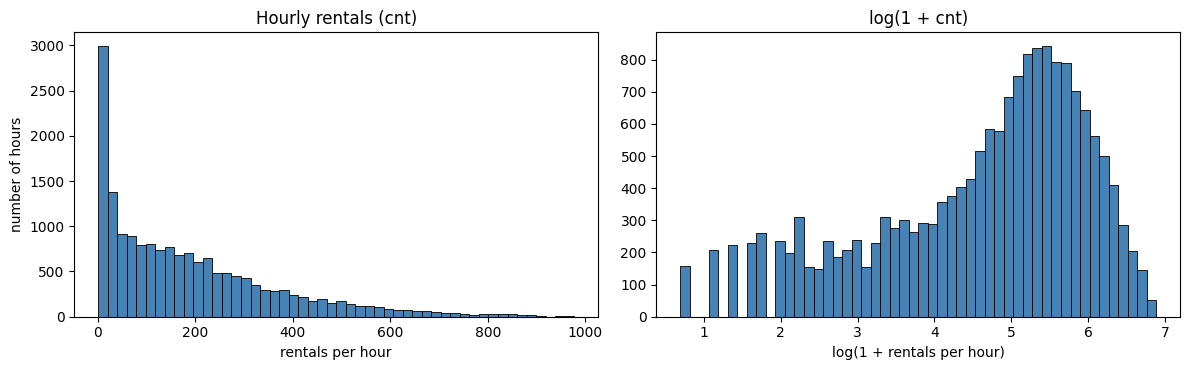

mean 189.5 | skew 1.28 | log1p skew -0.82
{0.1: 9.0, 0.25: 40.0, 0.5: 142.0, 0.75: 281.0, 0.9: 451.0, 0.95: 563.0, 0.99: 782.0}
Hours with < 20 rentals: 16.7% | hours with > 500: 7.4%


In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(hour.cnt, bins=50, color="steelblue", edgecolor="black", linewidth=0.6)
ax[0].set(title="Hourly rentals (cnt)", xlabel="rentals per hour", ylabel="number of hours")
ax[1].hist(np.log1p(hour.cnt), bins=50, color="steelblue", edgecolor="black", linewidth=0.6)
ax[1].set(title="log(1 + cnt)", xlabel="log(1 + rentals per hour)")
plt.tight_layout()
plt.savefig("01_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

q = hour.cnt.quantile([.1, .25, .5, .75, .9, .95, .99])
print("mean", round(hour.cnt.mean(), 1), "| skew", round(hour.cnt.skew(), 2), "| log1p skew", round(np.log1p(hour.cnt).skew(), 2))
print(q.round(0).to_dict())
print("Hours with < 20 rentals:", f"{(hour.cnt < 20).mean():.1%}", "| hours with > 500:", f"{(hour.cnt > 500).mean():.1%}")

### 3.2 Hourly demand pattern – working vs non-working days

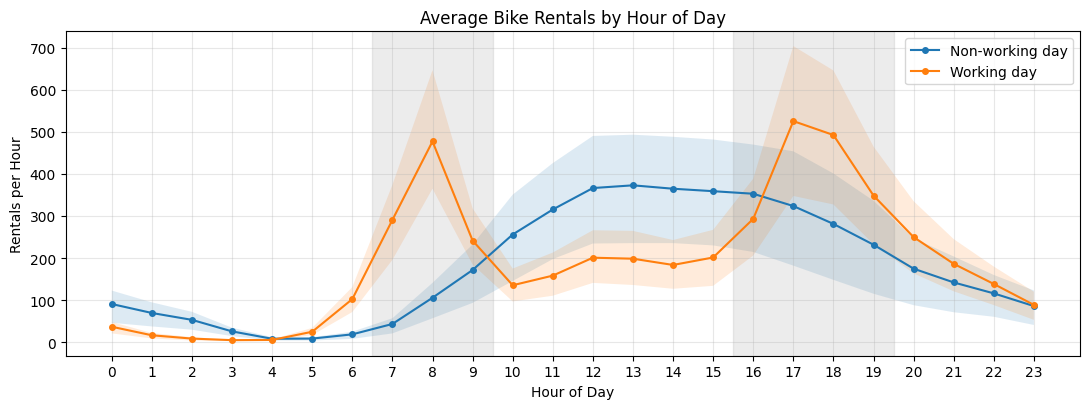


Average rentals at selected hours:
day_type  Non-working day  Working day
hr                                    
3                    26.0          5.0
7                    43.0        291.0
8                   106.0        477.0
9                   172.0        242.0
12                  366.0        201.0
13                  373.0        198.0
17                  324.0        525.0
18                  281.0        492.0
19                  232.0        348.0

Non-working day:
Peak hour: 13:00 = 373 rentals
Lowest hour: 4:00 = 8 rentals
Peak / average demand: 2.06x

Working day:
Peak hour: 17:00 = 525 rentals
Lowest hour: 3:00 = 5 rentals
Peak / average demand: 2.74x


In [22]:
# Calculate mean, 25th percentile and 75th percentile
prof = hour.groupby(["day_type", "hr"])["cnt"].agg(
    mean="mean",
    q25=lambda x: x.quantile(0.25),
    q75=lambda x: x.quantile(0.75)
)

# Create the plot
fig, ax = plt.subplots(figsize=(11, 4.2))

# Plot each day type
for dt in prof.index.get_level_values(0).unique():

    p = prof.loc[dt]

    ax.fill_between(
        p.index, p["q25"], p["q75"],
        alpha=0.15
    )

    ax.plot(
        p.index, p["mean"],
        marker="o",
        markersize=4,
        label=dt
    )

# Highlight morning and evening peak periods
ax.axvspan(6.5, 9.5, color="grey", alpha=0.15)
ax.axvspan(15.5, 19.5, color="grey", alpha=0.15)

# Labels and formatting
ax.set_title("Average Bike Rentals by Hour of Day")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Rentals per Hour")
ax.set_xticks(range(24))

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig("02_hourly_pattern.png", dpi=300, bbox_inches="tight")
plt.show()


# Create a comparison table
m = prof["mean"].unstack(0)

print("\nAverage rentals at selected hours:")
print(m.loc[[3, 7, 8, 9, 12, 13, 17, 18, 19]].round(0))


# Find peak and lowest demand hours
for dt in m.columns:

    s = m[dt]

    print(
        f"\n{dt}:"
        f"\nPeak hour: {s.idxmax()}:00 = {s.max():.0f} rentals"
        f"\nLowest hour: {s.idxmin()}:00 = {s.min():.0f} rentals"
        f"\nPeak / average demand: {s.max() / s.mean():.2f}x"
    )

### 3.3 Demand across weekdays (daily totals)

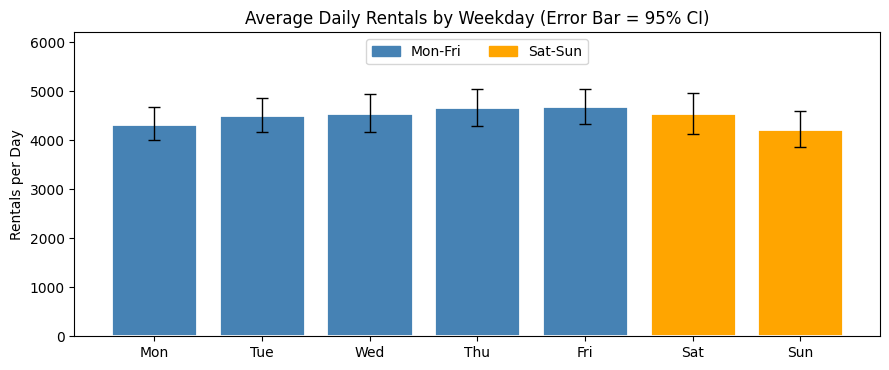

       mean   ci95  count
day                      
Mon  4338.0  343.0    105
Tue  4511.0  351.0    104
Wed  4549.0  392.0    104
Thu  4667.0  373.0    104
Fri  4690.0  360.0    104
Sat  4551.0  420.0    105
Sun  4229.0  358.0    105


In [24]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Define weekday order
order = [1, 2, 3, 4, 5, 6, 0]

# Map weekday numbers to names
names = {
    0: "Sun", 1: "Mon", 2: "Tue",
    3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat"
}

# Calculate mean, standard deviation and count
wk = day.groupby("weekday")["cnt"].agg(
    ["mean", "std", "count"]
).loc[order]

# Calculate 95% confidence interval
wk["ci95"] = 1.96 * wk["std"] / np.sqrt(wk["count"])

# Assign colours: weekdays = blue, weekends = orange
colors = [
    "steelblue" if d in (1, 2, 3, 4, 5) else "orange"
    for d in order
]

# Create bar chart
fig, ax = plt.subplots(figsize=(9, 3.8))

ax.bar(
    [names[d] for d in order],
    wk["mean"],
    yerr=wk["ci95"],
    color=colors,
    edgecolor="white",
    linewidth=2,
    capsize=4,
    error_kw={"ecolor": "black", "elinewidth": 1}
)

# Add labels and title
ax.set(
    title="Average Daily Rentals by Weekday (Error Bar = 95% CI)",
    ylabel="Rentals per Day"
)

ax.set_ylim(0, 6200)

# Add legend
ax.legend(
    handles=[
        Patch(color="steelblue", label="Mon-Fri"),
        Patch(color="orange", label="Sat-Sun")
    ],
    loc="upper center",
    ncol=2
)

plt.tight_layout()
plt.savefig("03_weekday.png", dpi=300, bbox_inches="tight")
plt.show()

# Display results
result = wk.assign(
    day=[names[d] for d in order]
).set_index("day")[["mean", "ci95", "count"]]

print(result.round(0))

### 3.4 Working-day vs non-working-day daily demand (split by year)

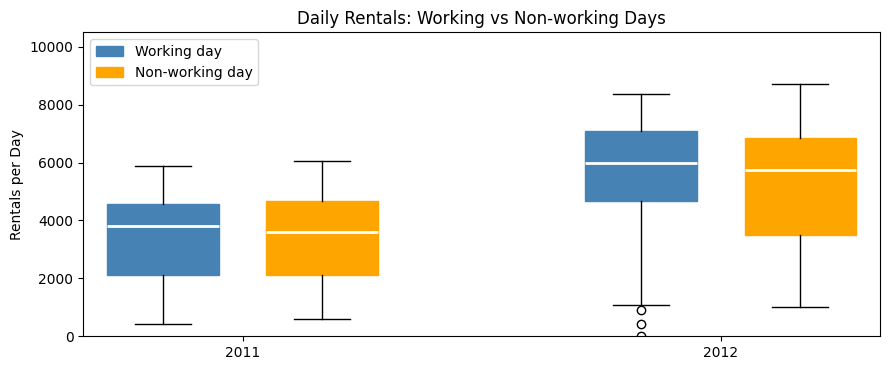

                    count    mean  median     std
yr day_type                                      
0  Non-working day    115  3364.0  3606.0  1545.0
   Working day        250  3425.0  3794.0  1298.0
1  Non-working day    116  5288.0  5748.0  2048.0
   Working day        250  5745.0  5989.0  1639.0


In [25]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(9, 3.8))

data = []
pos = []
cols = []

# Collect data for each year and day type
for i, yr in enumerate([0, 1]):

    for j, dt in enumerate(["Working day", "Non-working day"]):

        data.append(
            day.loc[
                (day["yr"] == yr) & (day["day_type"] == dt),
                "cnt"
            ]
        )

        pos.append(i * 3 + j)

        cols.append(
            "steelblue" if dt == "Working day" else "orange"
        )

# Create box plot
bp = ax.boxplot(
    data,
    positions=pos,
    widths=0.7,
    patch_artist=True,
    medianprops={"color": "white", "linewidth": 2}
)

# Apply colours
for patch, c in zip(bp["boxes"], cols):
    patch.set_facecolor(c)
    patch.set_edgecolor(c)

# Set year labels
ax.set_xticks([0.5, 3.5])
ax.set_xticklabels(["2011", "2012"])

# Add title and labels
ax.set(
    title="Daily Rentals: Working vs Non-working Days",
    ylabel="Rentals per Day",
    ylim=(0, 10500)
)

# Add legend
ax.legend(
    handles=[
        Patch(color="steelblue", label="Working day"),
        Patch(color="orange", label="Non-working day")
    ],
    loc="upper left"
)

plt.tight_layout()
plt.savefig("04_working_vs_nonworking.png",
            dpi=300, bbox_inches="tight")
plt.show()

# Display statistical summary
print(
    day.groupby(["yr", "day_type"])["cnt"]
    .agg(["count", "mean", "median", "std"])
    .round(0)
)

### 3.5 Monthly and seasonal demand

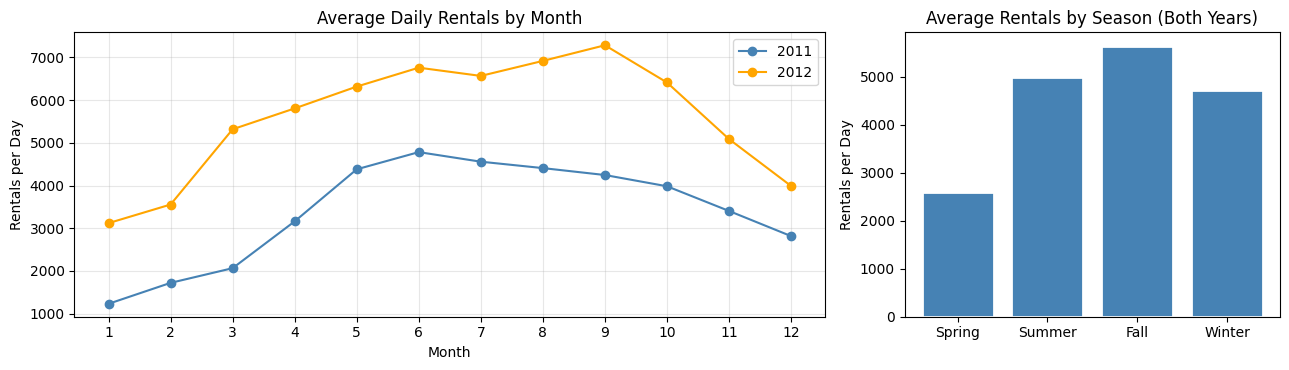


Monthly Average Rentals:
mnth      1       2       3       4       5       6       7       8       9   \
yr                                                                             
2011  1232.0  1722.0  2066.0  3162.0  4381.0  4784.0  4559.0  4409.0  4247.0   
2012  3121.0  3556.0  5319.0  5807.0  6318.0  6761.0  6568.0  6919.0  7286.0   

mnth      10      11      12  
yr                            
2011  3984.0  3406.0  2817.0  
2012  6414.0  5089.0  3991.0  

Seasonal Average Rentals:
{1: 2604.0, 2: 4992.0, 3: 5644.0, 4: 4728.0}

Peak Month / Lowest Month Ratio:
{0: 3.88, 1: 2.33}


In [26]:
import matplotlib.pyplot as plt

# Calculate average rentals by month and year
mon = day.groupby(["yr", "mnth"])["cnt"].mean().unstack(0)

# Create two plots side by side
fig, ax = plt.subplots(
    1, 2,
    figsize=(13, 3.8),
    gridspec_kw={"width_ratios": [2, 1]}
)

# Graph 1: Monthly demand comparison
ax[0].plot(
    mon.index, mon[0],
    color="steelblue", marker="o", label="2011"
)

ax[0].plot(
    mon.index, mon[1],
    color="orange", marker="o", label="2012"
)

ax[0].set(
    title="Average Daily Rentals by Month",
    xlabel="Month",
    ylabel="Rentals per Day",
    xticks=range(1, 13)
)

ax[0].legend()
ax[0].grid(alpha=0.3)

# Graph 2: Seasonal demand
sea = day.groupby("season")["cnt"].mean()

ax[1].bar(
    ["Spring", "Summer", "Fall", "Winter"],
    sea.values,
    color="steelblue",
    edgecolor="white",
    linewidth=2
)

ax[1].set(
    title="Average Rentals by Season (Both Years)",
    ylabel="Rentals per Day"
)

# Save and display
plt.tight_layout()
plt.savefig("05_monthly_seasonal.png", dpi=300, bbox_inches="tight")
plt.show()

# Display monthly results
print("\nMonthly Average Rentals:")
print(
    mon.rename(columns={0: "2011", 1: "2012"})
    .round(0).T
)

# Display seasonal results
print("\nSeasonal Average Rentals:")
print(sea.round(0).to_dict())

# Compare peak and lowest months
print("\nPeak Month / Lowest Month Ratio:")
print((mon.max() / mon.min()).round(2).to_dict())

### 3.6 Demand under different weather conditions

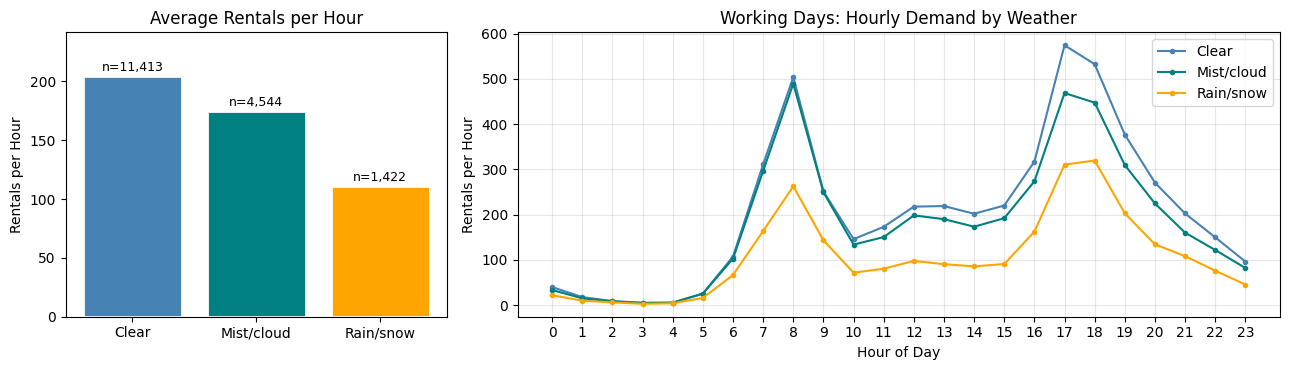

Average rentals across all hours:
{1: 205.0, 2: 175.0, 3: 112.0}

Average rentals during working-day rush hours:
{1: 414.0, 2: 358.0, 3: 226.0}

Rain vs clear: -45%
Mist vs clear: -14%

Share of hours with rain/snow: 8.2%


In [27]:
import matplotlib.pyplot as plt

# Weather category names
wnames = {
    1: "Clear",
    2: "Mist/cloud",
    3: "Rain/snow"
}

# Weather category colours
wcol = {
    1: "steelblue",
    2: "teal",
    3: "orange"
}

# Create two graphs
fig, ax = plt.subplots(
    1, 2,
    figsize=(13, 3.8),
    gridspec_kw={"width_ratios": [1, 2]}
)

# Graph 1: Average rentals by weather
wm = hour.groupby("weather")["cnt"].agg(["mean", "count"])

ax[0].bar(
    [wnames[w] for w in wm.index],
    wm["mean"],
    color=[wcol[w] for w in wm.index],
    edgecolor="white",
    linewidth=2
)

# Display number of observations above each bar
for i, (w, r) in enumerate(wm.iterrows()):
    ax[0].text(
        i,
        r["mean"] + 4,
        f"n={int(r['count']):,}",
        ha="center",
        color="black",
        fontsize=9
    )

ax[0].set(
    title="Average Rentals per Hour",
    ylabel="Rentals per Hour",
    ylim=(0, wm["mean"].max() * 1.18)
)

# Graph 2: Working-day hourly demand by weather
wp = hour[hour["workingday"] == 1].groupby(
    ["weather", "hr"]
)["cnt"].mean().unstack(0)

for w in wp.columns:
    ax[1].plot(
        wp.index,
        wp[w],
        color=wcol[w],
        marker="o",
        markersize=3,
        label=wnames[w]
    )

ax[1].set(
    title="Working Days: Hourly Demand by Weather",
    xlabel="Hour of Day",
    ylabel="Rentals per Hour",
    xticks=range(24)
)

ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("06_weather.png", dpi=300, bbox_inches="tight")
plt.show()


# Calculate average demand during rush hours
rush = hour[hour["rush_hour"] == 1].groupby("weather")["cnt"].mean()

print("Average rentals across all hours:")
print(wm["mean"].round(0).to_dict())

print("\nAverage rentals during working-day rush hours:")
print(rush.round(0).to_dict())

print(
    f"\nRain vs clear: {rush[3] / rush[1] - 1:+.0%}"
    f"\nMist vs clear: {rush[2] / rush[1] - 1:+.0%}"
)

# Percentage of observations with rain/snow
print(
    "\nShare of hours with rain/snow:",
    f"{(hour['weather'] == 3).mean():.1%}"
)

### 3.7–3.9 Temperature, humidity and wind speed vs demand
Binned averages (bins with at least 30 hours) are easier to read than a 17,000-point scatter.

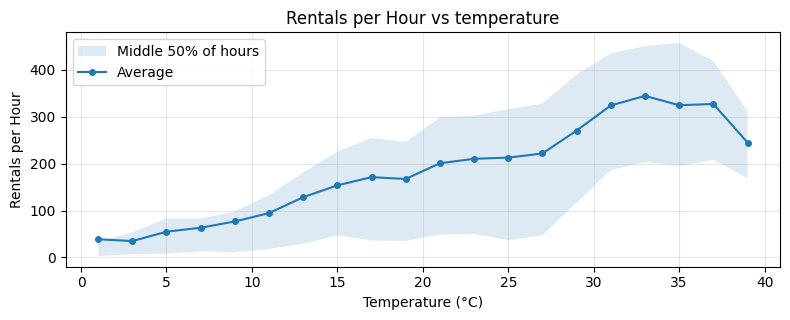


Temperature (°C):
Spearman correlation = +0.42
Highest bin average = 344 at 33.0
Lowest bin average = 35 at 3.0


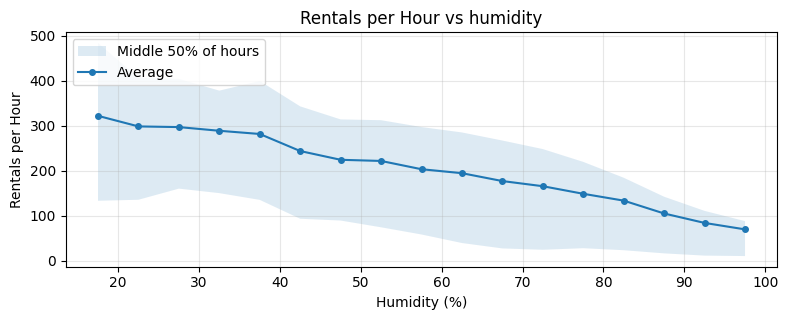


Humidity (%):
Spearman correlation = -0.36
Highest bin average = 322 at 17.5
Lowest bin average = 69 at 97.5


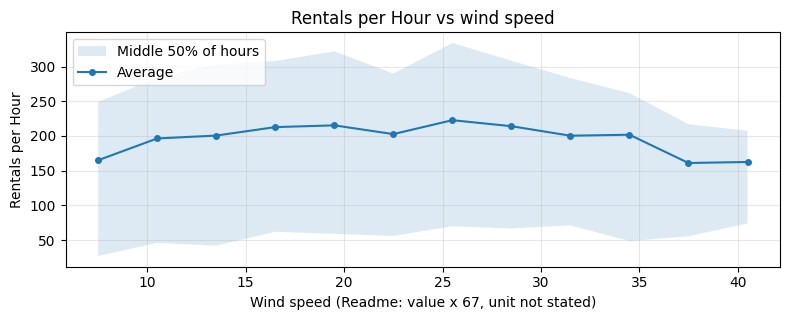


Wind speed (Readme: value x 67, unit not stated):
Spearman correlation = +0.13
Highest bin average = 223 at 25.5
Lowest bin average = 161 at 37.5

Working-day 17:00 analysis:
Spearman(temp, cnt) = 0.6
Spearman(hum, cnt) = -0.24

Mean humidity by weather: {1: 57.0, 2: 70.0, 3: 84.0}


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# Function to group a weather variable into bins
def binned(col, bins):

    # Divide the column into intervals
    b = pd.cut(hour[col], bins)

    # Calculate mean, count, 25th and 75th percentiles
    g = hour.groupby(b, observed=True)["cnt"].agg(
        mean="mean",
        count="count",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75)
    )

    # Keep bins having at least 30 observations
    g = g[g["count"] >= 30]

    # Replace interval labels with their midpoints
    g.index = [iv.mid for iv in g.index]

    return g


# Variables to analyse
specs = [
    ("temp_c", np.arange(0, 44, 2), "Temperature (°C)", "07_temperature"),
    ("hum_pct", np.arange(0, 105, 5), "Humidity (%)", "08_humidity"),
    ("wind_unscaled", np.arange(0, 60, 3), "Wind speed (Readme: value x 67, unit not stated)", "09_windspeed")
]


# Analyse each variable
for col, bins, label, fname in specs:

    g = binned(col, bins)

    # Create graph
    fig, ax = plt.subplots(figsize=(8, 3.3))

    ax.fill_between(
        g.index, g["q25"], g["q75"],
        alpha=0.15,
        label="Middle 50% of hours"
    )

    ax.plot(
        g.index, g["mean"],
        marker="o",
        markersize=4,
        label="Average"
    )

    ax.set(
        title=f"Rentals per Hour vs {label.split(' (')[0].lower()}",
        xlabel=label,
        ylabel="Rentals per Hour"
    )

    ax.legend(loc="upper left")
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(fname + ".png", dpi=300, bbox_inches="tight")
    plt.show()

    # Calculate Spearman correlation
    rho = spearmanr(hour[col], hour["cnt"]).statistic

    print(
        f"\n{label}:"
        f"\nSpearman correlation = {rho:+.2f}"
        f"\nHighest bin average = {g['mean'].max():.0f} "
        f"at {g['mean'].idxmax():.1f}"
        f"\nLowest bin average = {g['mean'].min():.0f} "
        f"at {g['mean'].idxmin():.1f}"
    )


# Investigate the relationship at a fixed hour on working days
sub = hour[
    (hour["workingday"] == 1) &
    (hour["hr"] == 17)
]

print("\nWorking-day 17:00 analysis:")

print(
    "Spearman(temp, cnt) =",
    round(spearmanr(sub["temp"], sub["cnt"]).statistic, 2)
)

print(
    "Spearman(hum, cnt) =",
    round(spearmanr(sub["hum"], sub["cnt"]).statistic, 2)
)


# Average humidity by weather condition
print(
    "\nMean humidity by weather:",
    hour.groupby("weather")["hum_pct"].mean().round(0).to_dict()
)

### 3.10 Demand trend over time

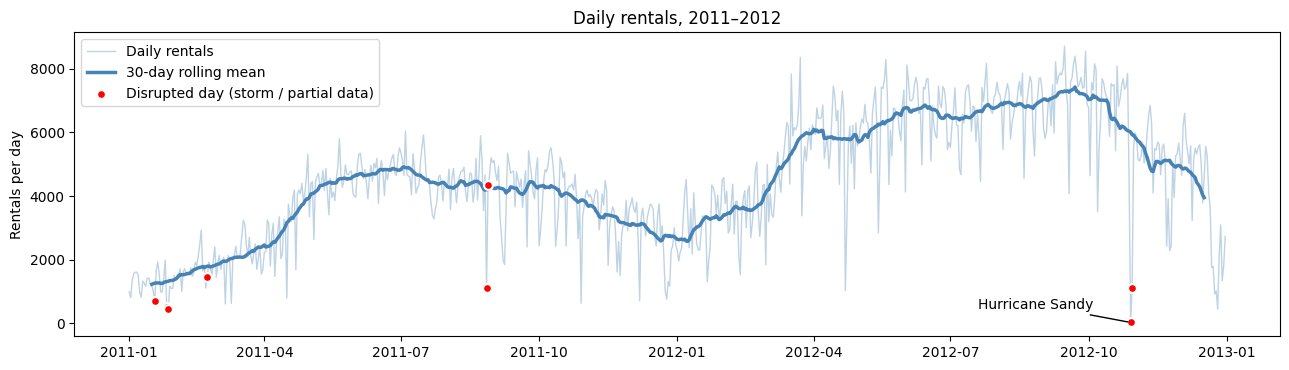

Average daily rentals: 2011 = 3406 | 2012 = 5600 | Growth = +64%
Same-month growth (2012 vs 2011): {1: 1.53, 2: 1.07, 3: 1.57, 4: 0.84, 5: 0.44, 6: 0.41, 7: 0.44, 8: 0.57, 9: 0.72, 10: 0.61, 11: 0.49, 12: 0.42}
Disrupted days: [{'dteday': datetime.date(2011, 1, 18), 'cnt': 683}, {'dteday': datetime.date(2011, 1, 26), 'cnt': 506}, {'dteday': datetime.date(2011, 1, 27), 'cnt': 431}, {'dteday': datetime.date(2011, 2, 22), 'cnt': 1450}, {'dteday': datetime.date(2011, 8, 27), 'cnt': 1115}, {'dteday': datetime.date(2011, 8, 28), 'cnt': 4334}, {'dteday': datetime.date(2012, 10, 29), 'cnt': 22}, {'dteday': datetime.date(2012, 10, 30), 'cnt': 1096}]


In [29]:
# Daily rental trend
s = day.set_index("dteday")["cnt"].sort_index()

fig, ax = plt.subplots(figsize=(13, 3.8))

# Actual daily rentals
ax.plot(
    s.index, s,
    color="steelblue",
    alpha=0.35,
    linewidth=1,
    label="Daily rentals"
)

# 30-day rolling average
ax.plot(
    s.index,
    s.rolling(window=30, center=True).mean(),
    color="steelblue",
    linewidth=2.5,
    label="30-day rolling mean"
)

# Highlight disrupted days
dis = day[day["disrupted_day"] == 1]

ax.scatter(
    dis["dteday"],
    dis["cnt"],
    color="red",
    s=40,
    zorder=3,
    edgecolor="white",
    linewidth=1.5,
    label="Disrupted day (storm / partial data)"
)

# Annotate Hurricane Sandy
sandy_date = pd.Timestamp("2012-10-29")

if sandy_date in s.index:
    ax.annotate(
        "Hurricane Sandy",
        (sandy_date, s.loc[sandy_date]),
        xytext=(-110, 10),
        textcoords="offset points",
        color="black",
        arrowprops={"arrowstyle": "-", "color": "black"}
    )

ax.set(
    title="Daily rentals, 2011–2012",
    ylabel="Rentals per day"
)

ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("10_trend.png", dpi=300, bbox_inches="tight")
plt.show()


# Compare average daily rentals across years
avg_2011 = s.loc["2011"].mean()
avg_2012 = s.loc["2012"].mean()

growth = (avg_2012 / avg_2011) - 1

print(
    "Average daily rentals:",
    "2011 =", round(avg_2011),
    "| 2012 =", round(avg_2012),
    f"| Growth = {growth:+.0%}"
)


# Compare the same months across both years
print(
    "Same-month growth (2012 vs 2011):",
    (mon[1] / mon[0] - 1).round(2).to_dict()
)


# Display disrupted days
print(
    "Disrupted days:",
    dis[["dteday", "cnt"]]
    .assign(dteday=dis["dteday"].dt.date)
    .to_dict("records")
)

### 3.11 Correlation heatmap

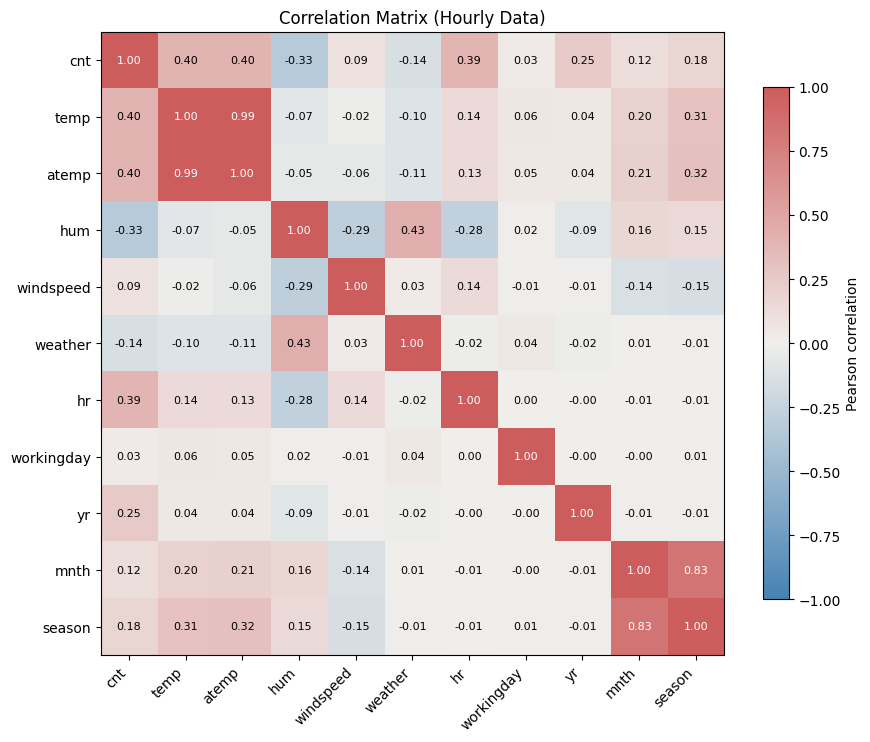

Correlation with cnt:
 temp          0.40
atemp         0.40
hr            0.39
hum          -0.33
yr            0.25
season        0.18
weather      -0.14
mnth          0.12
windspeed     0.09
workingday    0.03

temp vs atemp: 0.988 | season vs mnth: 0.83


In [30]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Select variables for correlation analysis
cols = [
    "cnt", "temp", "atemp", "hum", "windspeed",
    "weather", "hr", "workingday", "yr", "mnth", "season"
]

# Calculate Pearson correlation
corr = hour[cols].corr(method="pearson")

# Create colour gradient
cmap = LinearSegmentedColormap.from_list(
    "div",
    ["steelblue", "#f0efec", "indianred"]
)

# Plot heatmap
fig, ax = plt.subplots(figsize=(9, 7.5))

im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)

ax.set_xticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right")

ax.set_yticks(range(len(cols)))
ax.set_yticklabels(cols)

ax.grid(False)

# Display correlation values inside each cell
for i in range(len(cols)):
    for j in range(len(cols)):
        value = corr.iloc[i, j]

        ax.text(
            j, i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if abs(value) > 0.6 else "black"
        )

# Colour bar
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson correlation")

ax.set_title("Correlation Matrix (Hourly Data)")

plt.tight_layout()
plt.savefig("11_correlation.png", dpi=300, bbox_inches="tight")
plt.show()


# Correlation of each variable with bike rentals
print(
    "Correlation with cnt:\n",
    corr["cnt"].drop("cnt").sort_values(
        key=abs, ascending=False
    ).round(2).to_string()
)

# Check relationships between selected features
print(
    "\ntemp vs atemp:",
    round(corr.loc["temp", "atemp"], 3),
    "| season vs mnth:",
    round(corr.loc["season", "mnth"], 2)
)

### 3.12 Registered vs casual riders

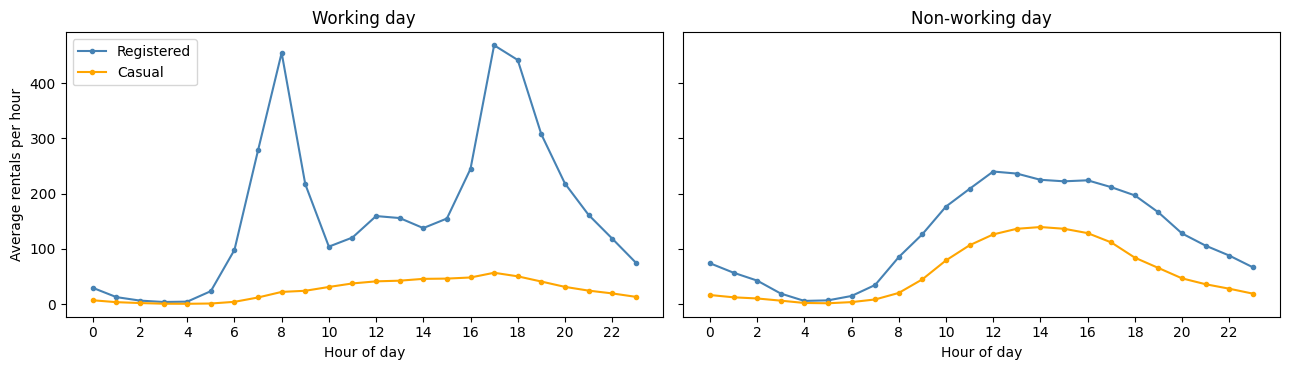

Casual share of rentals: {'Non-working day': 0.317, 'Working day': 0.132}
Share of each group's rentals that fall in peak hours:
                  casual  registered
day_type                           
Non-working day   0.291       0.297
Working day       0.352       0.526
Correlation of casual with temp: 0.46 | registered with temp: 0.34


In [31]:
import matplotlib.pyplot as plt

# Compare registered and casual rentals by hour
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)

for k, dt in enumerate(["Working day", "Non-working day"]):

    p = (
        hour[hour["day_type"] == dt]
        .groupby("hr")[["registered", "casual"]]
        .mean()
    )

    ax[k].plot(
        p.index, p["registered"],
        color="steelblue",
        marker="o",
        markersize=3,
        label="Registered"
    )

    ax[k].plot(
        p.index, p["casual"],
        color="orange",
        marker="o",
        markersize=3,
        label="Casual"
    )

    ax[k].set(
        title=dt,
        xlabel="Hour of day",
        xticks=range(0, 24, 2)
    )

ax[0].set_ylabel("Average rentals per hour")
ax[0].legend(loc="upper left")

plt.tight_layout()
plt.savefig("12_registered_vs_casual.png", dpi=300, bbox_inches="tight")
plt.show()


# Total rentals by rider type and day type
sh = hour.groupby("day_type")[["casual", "registered", "cnt"]].sum()

print(
    "Casual share of rentals:",
    (sh["casual"] / sh["cnt"]).round(3).to_dict()
)


# Share of each rider group's rentals occurring during peak hours
peak_hours = [7, 8, 9, 16, 17, 18]

peak_totals = (
    hour[hour["hr"].isin(peak_hours)]
    .groupby("day_type")[["casual", "registered"]]
    .sum()
)

all_totals = (
    hour.groupby("day_type")[["casual", "registered"]]
    .sum()
)

pk = peak_totals / all_totals

print(
    "Share of each group's rentals that fall in peak hours:\n",
    pk.round(3)
)


# Correlation between temperature and rentals by rider type
print(
    "Correlation of casual with temp:",
    round(hour["casual"].corr(hour["temp"]), 2),
    "| registered with temp:",
    round(hour["registered"].corr(hour["temp"]), 2)
)

### 3.13 EDA summary – what this means for the CEO's question

In [32]:
wd = hour[(hour.workingday == 1) & (hour.disrupted_day == 0)]
per_day = wd.groupby("dteday").cnt.agg(["max", "mean", "sum"])
per_day["peak_to_mean"] = per_day["max"] / per_day["mean"]
night_share = hour.loc[hour.night == 1, "cnt"].sum() / hour.cnt.sum()
print(f"Working days: median peak hour / average hour = {per_day.peak_to_mean.median():.2f}x")
print(f"Working days: median share of the day's rentals in the 7 peak hours = "
      f"{(wd[wd.hr.isin(fe.PEAK_HOURS)].groupby('dteday').cnt.sum() / per_day['sum']).median():.1%} (uniform would be {7/24:.1%})")
print(f"Share of all rentals between 00:00 and 05:59: {night_share:.1%}")

Working days: median peak hour / average hour = 2.91x
Working days: median share of the day's rentals in the 7 peak hours = 58.6% (uniform would be 29.2%)
Share of all rentals between 00:00 and 05:59: 3.2%


## 4. Hypothesis testing

### 4.1 Choosing the hypothesis (exploration on 2011 only)
To avoid "finding a hypothesis in the data and then testing it on the same data", the hypothesis is **formed on 2011** and **confirmed on 2012**, which it has not seen.
(2012 H2 is also the Phase 3 model test set. The hypothesis test fits no model, so this does not leak into model evaluation.)

Days kept: 723 of 731 (partial days removed: share would be distorted)


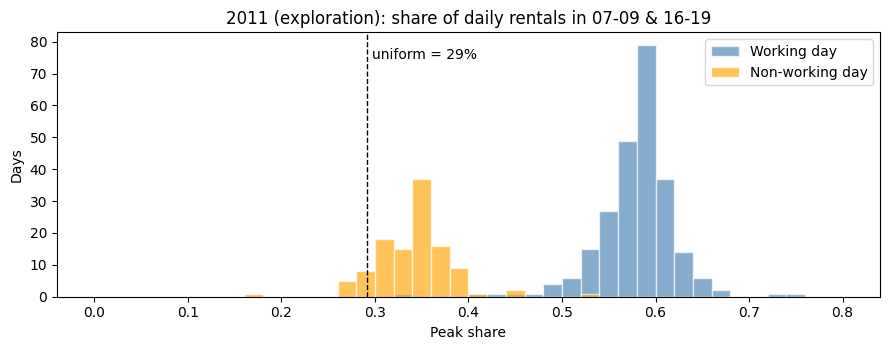

            count   mean    std    min    25%    50%   75%    max
workingday                                                       
0           113.0  0.341  0.042  0.175  0.317  0.345  0.36  0.535
1           246.0  0.579  0.042  0.335  0.562  0.583  0.60  0.749

For contrast — daily TOTAL rentals 2011 by day type: {0: 3375.0, 1: 3468.0}


In [34]:
# Calculate daily peak-hour share
daily = fe.daily_peak_share(hour, min_hours=22)

print(
    "Days kept:", len(daily), "of", hour.dteday.nunique(),
    "(partial days removed: share would be distorted)"
)

# Define colours
DAYTYPE_COLOR = {
    "Working day": "steelblue",
    "Non-working day": "orange"
}

explore = daily[daily.yr == 0]

fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.linspace(0, 0.8, 41)

for wdv, label in [(1, "Working day"), (0, "Non-working day")]:
    ax.hist(
        explore.loc[explore.workingday == wdv, "peak_share"],
        bins=bins,
        color=DAYTYPE_COLOR[label],
        alpha=0.65,
        label=label,
        edgecolor="white"
    )

ax.axvline(7 / 24, color="black", linestyle="--", linewidth=1)

ax.text(
    7 / 24 + 0.005,
    ax.get_ylim()[1] * 0.9,
    "uniform = 29%",
    color="black"
)

ax.set(
    title="2011 (exploration): share of daily rentals in 07-09 & 16-19",
    xlabel="Peak share",
    ylabel="Days"
)

ax.legend()

plt.tight_layout()
plt.savefig("13_peak_share_2011.png", dpi=300, bbox_inches="tight")
plt.show()

print(explore.groupby("workingday").peak_share.describe().round(3))

print(
    "\nFor contrast — daily TOTAL rentals 2011 by day type:",
    explore.groupby("workingday").cnt.mean().round(0).to_dict()
)

### 4.2 The hypothesis
**Metric:** *peak share* = rentals in the commute windows (07:00–09:59 and 16:00–19:59) ÷ the day's total rentals. One value per day.

- **H0:** mean peak share is the same on working days and non-working days.
- **H1:** mean peak share differs between working and non-working days (two-sided; 2011 suggests working days are higher).
- **α = 0.05.** Unit of analysis = one day. Confirmation sample = **2012** days with ≥ 22 recorded hours.

**Why this hypothesis and not "daily demand differs"?** The CEO's puzzle – *riders can't find bikes, yet bikes sit idle* – is exactly what you'd see if demand is fine in **total** but crowded into **a few hours**. A peak-share test checks that mechanism directly. The suggested daily-total test is run as well (4.5).

**Test choice:** Welch's t-test (does not assume equal variances; groups have unequal size ~250 vs ~115). With n > 100 per group the sampling distribution of the mean is close to normal even if days are not, but normality and variances are checked and a Mann–Whitney U test is reported as a robustness check.

,Value
Statistic,
n (working / non-working),248 / 116
Mean working,0.581
Mean non-working,0.343
Difference (A - B),0.238
95% CI of difference,"[0.229, 0.248]"
Welch t (df),47.81 (224)
"p-value (Welch, two-sided)",1.66e-119
Effect size Hedges' g,5.38
Levene p (equal variances?),0.786


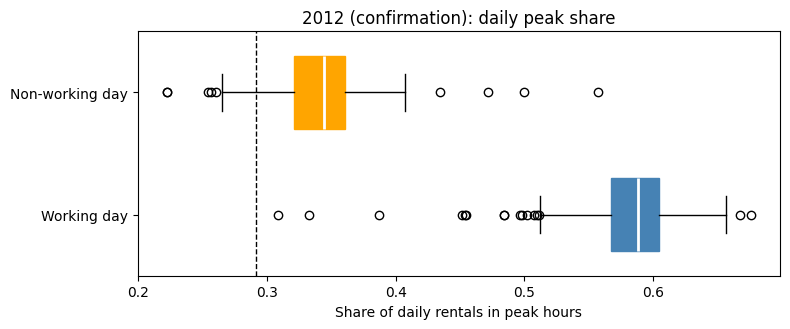

In [36]:

import sys
sys.path.append("/content/src")

import hypothesis_testing as ht

# Create output directory if it doesn't exist
os.makedirs("outputs/model_results", exist_ok=True)

# Select 2012 observations for confirmation
confirm = daily[daily["yr"] == 1].copy()

# Separate peak shares into working and non-working days
working = confirm.loc[
    confirm["workingday"] == 1, "peak_share"
]

non_working = confirm.loc[
    confirm["workingday"] == 0, "peak_share"
]

# Compare the two groups statistically
res = ht.compare_groups(
    working,
    non_working,
    label_a="working",
    label_b="non-working"
)

display(ht.format_result(res))

# Save statistical test results
pd.DataFrame([res]).to_csv(
    "outputs/model_results/hypothesis_peak_share_2012.csv",
    index=False
)

# Visualize the comparison
fig, ax = plt.subplots(figsize=(8, 3.4))

bp = ax.boxplot(
    [working, non_working],
    vert=False,
    widths=0.6,
    patch_artist=True,
    medianprops={"color": "white", "linewidth": 2}
)

# Colour the two boxplots
for patch, color in zip(bp["boxes"], ["steelblue", "orange"]):
    patch.set_facecolor(color)
    patch.set_edgecolor(color)

ax.set_yticks([1, 2])
ax.set_yticklabels(["Working day", "Non-working day"])

# Uniform-distribution benchmark
uniform_share = len(fe.PEAK_HOURS) / 24

ax.axvline(
    uniform_share,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set(
    title="2012 (confirmation): daily peak share",
    xlabel="Share of daily rentals in peak hours"
)

plt.tight_layout()
plt.savefig(
    "14_peak_share_2012_test.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

**Results on 2012 (not used to form the hypothesis):**

| | |
|---|---|
| Mean peak share | **working 0.581** vs **non-working 0.343** (n = 248 / 116 days) |
| Difference | **+23.8 percentage points**, 95% CI **[22.9, 24.8]** |
| Welch t | 47.8 (df 224), **p ≈ 1.7 × 10⁻¹¹⁹** |
| Effect size | Hedges' g = **5.38** (anything above 0.8 is "large") |
| Assumptions | Levene p = 0.79 (variances similar; Welch is safe either way). Shapiro rejects normality, but with 116+ days per group the mean is approximately normal (CLT) |
| Robustness | Mann–Whitney U p ≈ 1.1 × 10⁻⁵¹, rank-biserial 0.98 – same conclusion without the normality assumption |
| **Decision** | **Reject H0** at α = 0.05 |

**Business interpretation.** On working days, **about 58% of rentals are squeezed into 7 hours**, compared with 34% on non-working days. The direction is unsurprising (people commute); what matters is the **size**: availability on working days is decided by a few hours, not by daily volume.



### 4.3 Assumptions and confounders
- **Independence:** consecutive days are correlated (weather spells, trend). The t-test treats days as independent, so its p-value is somewhat optimistic. → handled in 4.4 with autocorrelation-robust (Newey–West) standard errors.
- **Confounding:** working and non-working days could differ in season, weather or year mix (e.g. holidays cluster in winter). → controlled in 4.4 by regression.
- **Causation:** even after controls, this shows *association*. The working-day effect is plausibly causal (commuting), but the test itself does not prove it.

In [37]:
X = pd.get_dummies(daily[["workingday", "yr", "season", "weather_mean", "temp", "hum", "windspeed"]],
                   columns=["season"], drop_first=True, dtype=float)
reg = ht.ols_hac(daily.peak_share, X, maxlags=7)
display(reg.round(4))
print(f"R² = {reg.attrs['r2']:.3f}, n = {reg.attrs['n']} days, Newey-West lags = 7")
print("Day-type mix check (share of each season among working / non-working days):")
print(pd.crosstab(daily.workingday, daily.season, normalize="index").round(2))
reg.to_csv("outputs/model_results/hypothesis_peak_share_regression.csv")

,coef,hac_se,t,p_value,ci_low,ci_high
const,0.3513,0.0118,29.7962,0.0000,0.3282,0.3744
workingday,0.2383,0.0037,65.1755,0.0000,0.2311,0.2455
yr,0.0019,0.0035,0.5343,0.5933,-0.0049,0.0087
weather_mean,0.0004,0.0055,0.0698,0.9444,-0.0104,0.0112
temp,-0.0177,0.0151,-1.1733,0.2411,-0.0472,0.0119
hum,-0.0079,0.0163,-0.4822,0.6298,-0.0399,0.0241
windspeed,-0.0038,0.0226,-0.1673,0.8672,-0.0480,0.0404
season_2,0.0086,0.0061,1.4217,0.1555,-0.0033,0.0205
season_3,0.0029,0.0072,0.4044,0.6861,-0.0112,0.0171
season_4,0.0024,0.0066,0.3641,0.7159,-0.0105,0.0153


R² = 0.870, n = 723 days, Newey-West lags = 7
Day-type mix check (share of each season among working / non-working days):
season         1     2     3     4
workingday                        
0           0.27  0.24  0.24  0.25
1           0.23  0.26  0.27  0.24


### 4.5 The suggested test – do daily *totals* differ? (day.csv, 2011–2012)

In [38]:
res_tot = ht.compare_groups(day.loc[day.workingday == 1, "cnt"], day.loc[day.workingday == 0, "cnt"],
                            label_a="working", label_b="non-working")
display(ht.format_result(res_tot, value_fmt="{:.0f}"))

Xd = pd.get_dummies(day[["workingday", "yr", "season", "weather", "temp", "hum", "windspeed"]],
                    columns=["season", "weather"], drop_first=True, dtype=float)
reg_tot = ht.ols_hac(day.cnt, Xd, maxlags=7)
display(reg_tot.round({"coef": 1, "hac_se": 1, "t": 2, "p_value": 4, "ci_low": 1, "ci_high": 1}))
print(f"R² = {reg_tot.attrs['r2']:.3f}")
pd.DataFrame([res_tot]).to_csv("outputs/model_results/hypothesis_daily_total.csv", index=False)

,Value
Statistic,
n (working / non-working),500 / 231
Mean working,4585
Mean non-working,4330
Difference (A - B),255
95% CI of difference,"[-58, 567]"
Welch t (df),1.60 (414)
"p-value (Welch, two-sided)",1.10e-01
Effect size Hedges' g,0.13
Levene p (equal variances?),0.0375


,coef,hac_se,t,p_value,ci_low,ci_high
const,1570.2,289.0,5.43,0.0000,1003.7,2136.7
workingday,175.4,75.9,2.31,0.0210,26.8,324.1
yr,2009.2,108.8,18.46,0.0000,1795.9,2222.6
temp,5116.4,620.3,8.25,0.0000,3900.7,6332.2
hum,-1393.4,363.8,-3.83,0.0001,-2106.5,-680.3
windspeed,-2829.2,496.1,-5.70,0.0000,-3801.5,-1856.8
season_2,1142.1,203.2,5.62,0.0000,743.7,1540.5
season_3,847.6,296.6,2.86,0.0044,266.3,1429.0
season_4,1542.7,179.0,8.62,0.0000,1191.9,1893.5
weather_2,-413.4,81.0,-5.11,0.0000,-572.1,-254.7


R² = 0.820


### 4.6 Design of experiment – testing the decision, not just the pattern
The tests above show *when* demand happens. The CEO's decision needs a **causal** answer: *does repositioning bikes fix availability more cheaply than buying bikes?* This dataset cannot answer that (no station data, no failed rentals), so I would run a pilot:

| Element | Design |
|---|---|
| **Operational hypothesis** | Pre-positioning bikes at high-demand stations before the commute peaks reduces empty-station time during peaks, without adding bikes. |
| **Treatment** | Rebalancing trucks fill the top morning-origin stations before 07:00 and the top evening-origin (office-area) stations before 16:00. |
| **Control** | Current operations. |
| **Randomisation** | *Switchback design*: working days are randomly assigned to treatment or control within each week (or station zones are randomised), so weather, season and growth are balanced between arms. |
| **Primary metric** | Minutes with zero bikes at target stations during 07–09 and 16–19 (from dock-status logs). |
| **Secondary metrics** | Peak-hour rentals, "no bike available" app events, complaints, rebalancing cost (truck-hours, km). |
| **Guardrails** | Empty/full-dock minutes at non-target stations (are we just moving the problem?). |
| **Duration and power** | 4–6 weeks; sample size set from the historical day-to-day variance of empty-station minutes. |
| **Decision rule** | If rebalancing brings peak availability to target at a lower cost per avoided stockout than the yearly cost of an extra bike → **don't buy**; buy only for stations that stay empty *after* rebalancing. |

## Phase 2 summary

**Completed**
- Cleaning applied and logged (humidity imputed, weather 4 merged, wind zeros and storm days flagged, nothing deleted).
- 21 model features, each with a documented reason, plus an explicit list of excluded columns (leakage, redundancy).
- 12 EDA charts with interpretations, plus the hypothesis charts (saved in `outputs/charts/`).
- Hypothesis formed on 2011 and confirmed on 2012: peak share is **+23.8 pp** higher on working days (p ≈ 10⁻¹¹⁹; holds after controls). The suggested daily-total test is **not significant** (p = 0.11; +4% after controls).
- Experiment design for the operational decision.

**Carried into Phase 3**
- Target `cnt`; features = `fe.MODEL_FEATURES`. For the linear model, drop `is_weekend` (collinear).
- Chronological split with training through June 2012; the test set (Jul–Dec 2012) is untouched so far.
- Test a log target and a "same hour last week" lag variant instead of assuming them.

**Limitations still open**
- No station data, trip durations, or failed rentals, so shortages can't be observed directly.
- Night averages are slightly overstated (zero-rental hours are missing from the file).
- 2011–12 growth makes any multi-year fleet projection uncertain.